
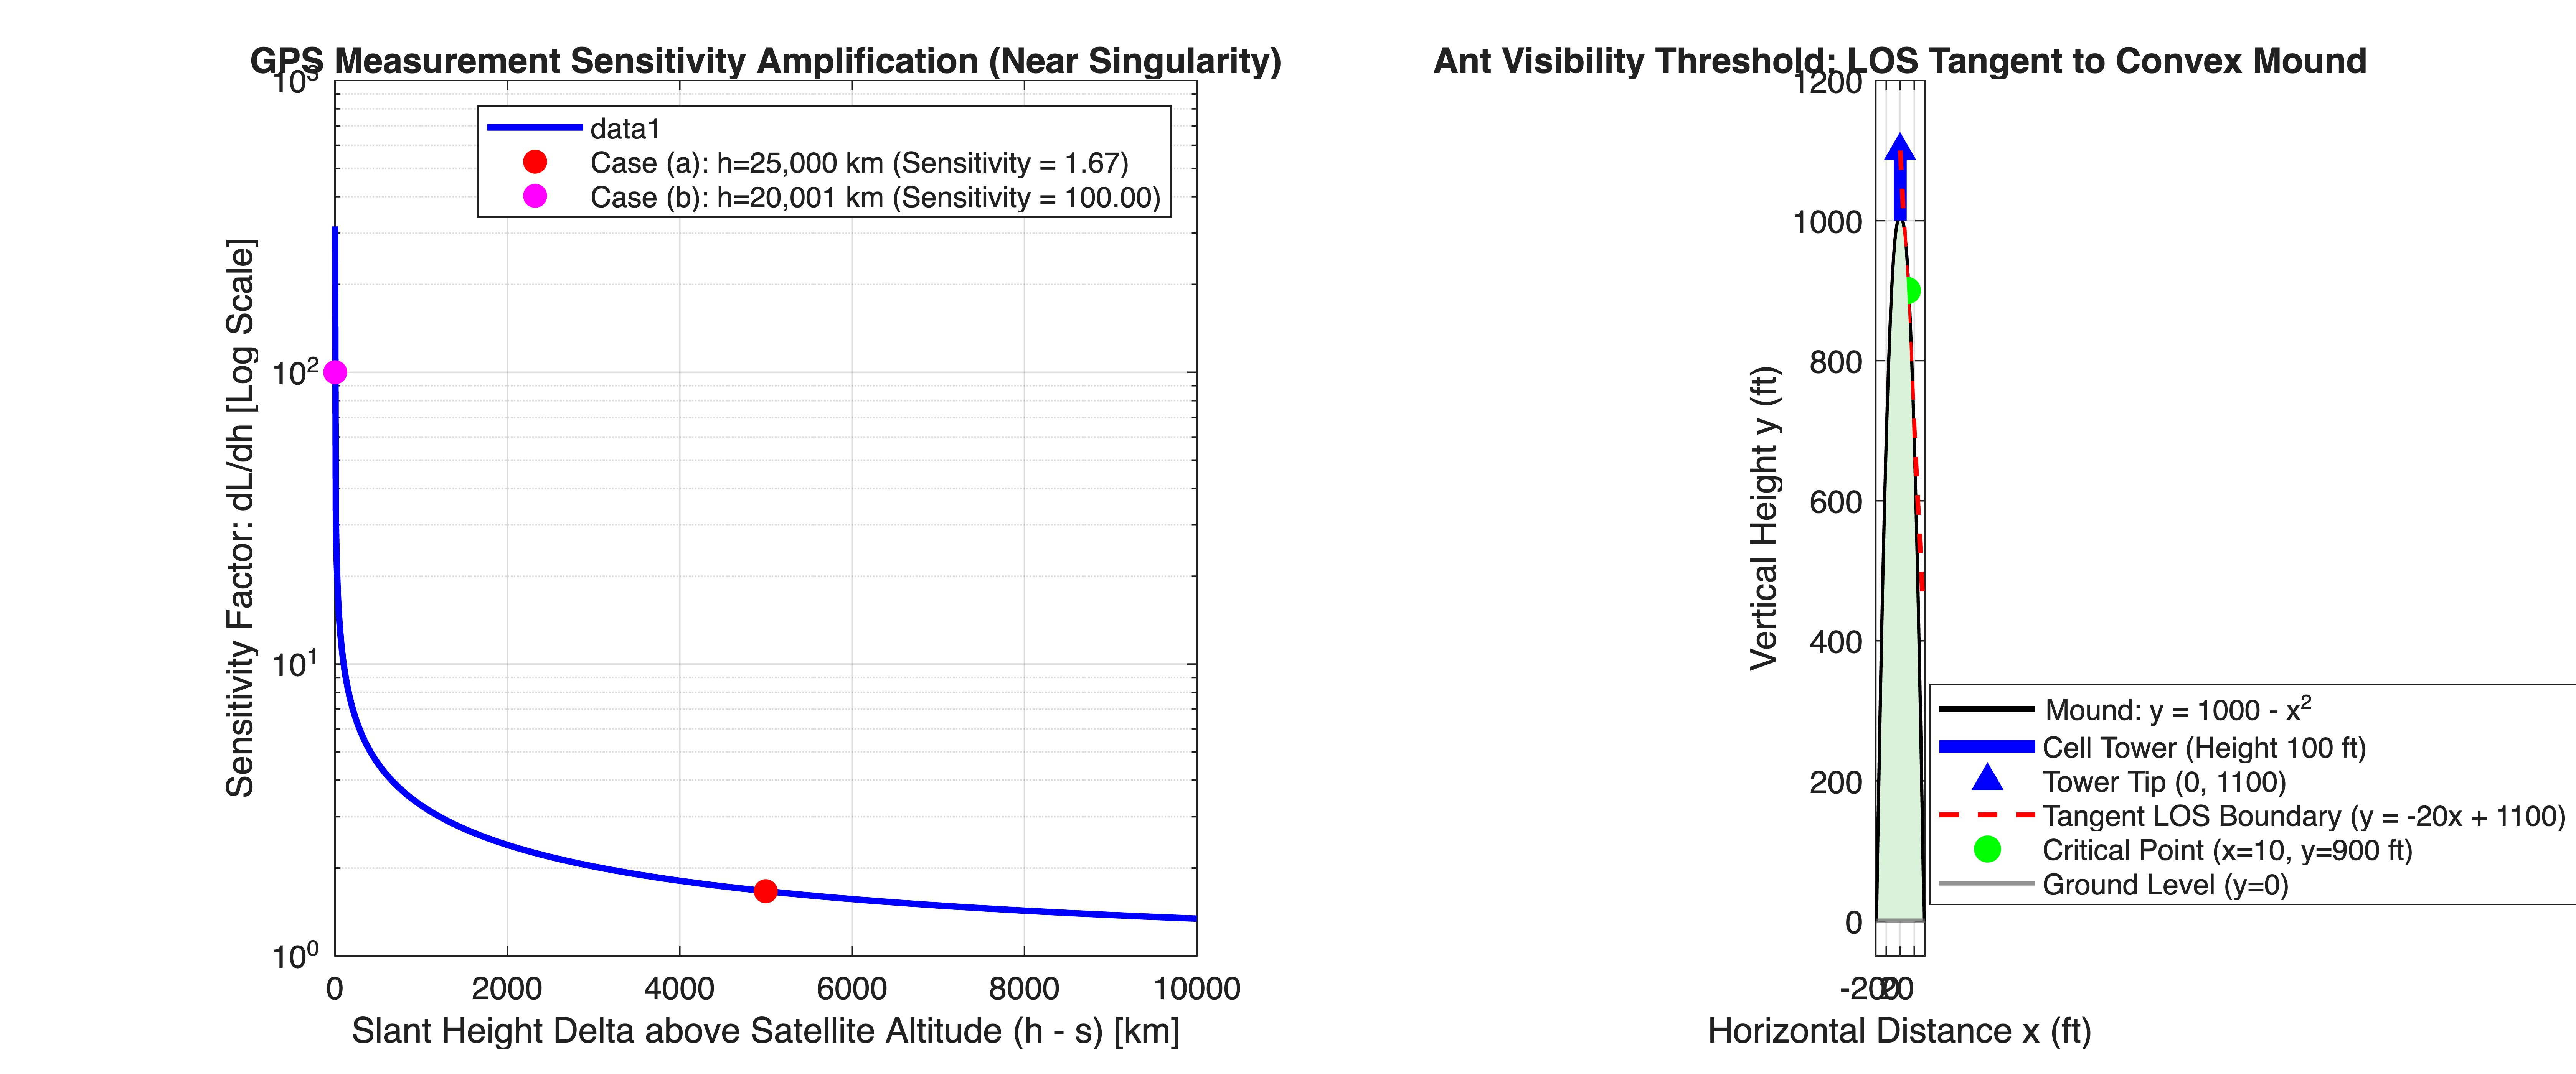

In [1]:
%% MIT 18.01 Problem Set 1: Kinematics, Sensitivity, and Geometry Simulation
% Mathematical Tool Application: Analyzes measurement sensitivity amplification
% near singularities (GDOP in navigation) and computes line-of-sight (LOS)
% boundary tangency for sensor occlusion in path planning.


clear; clc; close all;


%% Part 1: GPS Slant-Range Sensitivity & Error Propagation (Problem 2)
% Flat planet model: L(h) = sqrt(h^2 - s^2), where s = 20,000 km
s_alt = 20000;
h_domain = linspace(s_alt + 0.1, 30000, 1000);
L_domain = sqrt(h_domain.^2 - s_alt^2);
sensitivity_domain = h_domain ./ L_domain; % dL/dh


% Case evaluations
h_case_a = 25000;
L_case_a = sqrt(h_case_a^2 - s_alt^2); % 15,000 km
sens_a = h_case_a / L_case_a;          % 25000/15000 = 5/3 approx 1.667


h_case_b = 20001;
L_case_b = sqrt(h_case_b^2 - s_alt^2); % approx 200.00 km
sens_b = h_case_b / L_case_b;          % 20001/200 approx 100.00


figure('Color', 'w', 'Position', [100, 100, 1200, 500]);


subplot(1, 2, 1);
semilogy(h_domain - s_alt, sensitivity_domain, 'b-', 'LineWidth', 2); hold on;
plot(h_case_a - s_alt, sens_a, 'ro', 'MarkerFaceColor', 'r', 'MarkerSize', 7, ...
    'DisplayName', sprintf('Case (a): h=25,000 km (Sensitivity = %.2f)', sens_a));
plot(h_case_b - s_alt, sens_b, 'mo', 'MarkerFaceColor', 'm', 'MarkerSize', 7, ...
    'DisplayName', sprintf('Case (b): h=20,001 km (Sensitivity = %.2f)', sens_b));


grid on;
xlabel('Slant Height Delta above Satellite Altitude (h - s) [km]');
ylabel('Sensitivity Factor: dL/dh [Log Scale]');
title('GPS Measurement Sensitivity Amplification (Near Singularity)');
legend('Location', 'northeast');
%% Part 2: Ant on Mound Line-of-Sight Visibility (Problem 3)
% Mound: y = 1000 - x^2. Ground level: y = 0 => x = +/- sqrt(1000)
% Tower top: (0, 1100). Tangent point derived analytically: x0 = 10, y0 = 900.
x_mound = linspace(-sqrt(1000), sqrt(1000), 400);
y_mound = 1000 - x_mound.^2;


x0_tangent = 10;
y0_tangent = 900;
slope_tangent = -2 * x0_tangent; % -20


% Tangent line of sight: y - 1100 = -20*x => y = -20*x + 1100
x_los = linspace(0, sqrt(1000), 200);
y_los = -20 * x_los + 1100;


subplot(1, 2, 2);
plot(x_mound, y_mound, 'k-', 'LineWidth', 2, 'DisplayName', 'Mound: y = 1000 - x^2'); hold on;
plot([0, 0], [1000, 1100], 'b-', 'LineWidth', 4, 'DisplayName', 'Cell Tower (Height 100 ft)');
plot(0, 1100, 'b^', 'MarkerFaceColor', 'b', 'MarkerSize', 8, 'DisplayName', 'Tower Tip (0, 1100)');
plot(x_los, y_los, 'r--', 'LineWidth', 1.5, 'DisplayName', 'Tangent LOS Boundary (y = -20x + 1100)');
plot(x0_tangent, y0_tangent, 'go', 'MarkerFaceColor', 'g', 'MarkerSize', 8, ...
    'DisplayName', sprintf('Critical Point (x=10, y=900 ft)'));


% Ground line
yline(0, 'Color', [0.4 0.4 0.4], 'LineWidth', 1.5, 'DisplayName', 'Ground Level (y=0)');


% Fill occluded region below mound
fill([x_mound, 0], [y_mound, 0], [0.85, 0.95, 0.85], 'EdgeColor', 'none', 'HandleVisibility', 'off');


axis equal; grid on;
xlim([-35, 35]); ylim([-50, 1200]);
xlabel('Horizontal Distance x (ft)');
ylabel('Vertical Height y (ft)');
title('Ant Visibility Threshold: LOS Tangent to Convex Mound');
legend('Location', 'northeast');